In [22]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

df = pd.read_csv("student_performance_dataset.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   str    
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          898 non-null    str    
 6   internet_access             1000 non-null   str    
 7   extracurricular_activities  1000 non-null   str    
 8   part_time_job               1000 non-null   str    
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   str    
dtypes: float64(5), int64(1), str(6)
memory usage: 115.4 KB


In [23]:
df.head()

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [24]:
df.isnull()

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,True,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
995,False,False,False,False,False,False,False,False,False,False,False,False
996,False,False,False,False,False,True,False,False,False,False,False,False
997,False,False,False,False,False,False,False,False,False,False,False,False
998,False,False,False,False,False,False,False,False,False,False,False,False


In [25]:
df['parental_education'] = df['parental_education'].fillna('nessuna_istruzione')

In [26]:
df["parental_education"].value_counts()

parental_education
High School           356
Bachelors             308
Masters               184
nessuna_istruzione    102
PhD                    50
Name: count, dtype: int64

In [27]:
df = pd.get_dummies(df, columns=['gender', 'internet_access', 'extracurricular_activities', 'part_time_job'], drop_first=True)

In [28]:
valori = ['nessuna_istruzione', 'High School', 'Bachelors', 'Masters', 'PhD']
df["parental_education"] = df["parental_education"].map({v: i for i, v in enumerate(valori)})

In [29]:
df["final_grade"].value_counts()

final_grade
B    354
A    284
C    261
D     89
F     12
Name: count, dtype: int64

In [30]:
ordine_voti = ['F', 'D', 'C', 'B', 'A']
df['final_grade'] = df['final_grade'].map({v: i for i, v in enumerate(ordine_voti)})

In [31]:
df['final_grade'].value_counts()

final_grade
3    354
4    284
2    261
1     89
0     12
Name: count, dtype: int64

In [32]:
df.groupby('final_grade')['final_exam_score'].agg(['min', 'max'])

,min,max
final_grade,,
0,46.8,59.7
1,60.0,69.9
2,70.0,79.9
3,80.0,89.9
4,90.0,100.0


In [33]:
df['final_grade'] = df['final_grade'].replace({0: 1})

In [34]:
df['final_grade'].value_counts()

final_grade
3    354
4    284
2    261
1    101
Name: count, dtype: int64

In [35]:
X = df.drop(columns=['student_id', 'final_grade', 'final_exam_score'])
y = df['final_grade']

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   student_id                      1000 non-null   int64  
 1   study_time_hours                1000 non-null   float64
 2   attendance_percent              1000 non-null   float64
 3   sleep_hours                     1000 non-null   float64
 4   parental_education              1000 non-null   int64  
 5   previous_grade                  1000 non-null   float64
 6   final_exam_score                1000 non-null   float64
 7   final_grade                     1000 non-null   int64  
 8   gender_Male                     1000 non-null   bool   
 9   internet_access_Yes             1000 non-null   bool   
 10  extracurricular_activities_Yes  1000 non-null   bool   
 11  part_time_job_Yes               1000 non-null   bool   
dtypes: bool(4), float64(5), int64(3)
memory usage:

<Axes: xlabel='final_grade'>

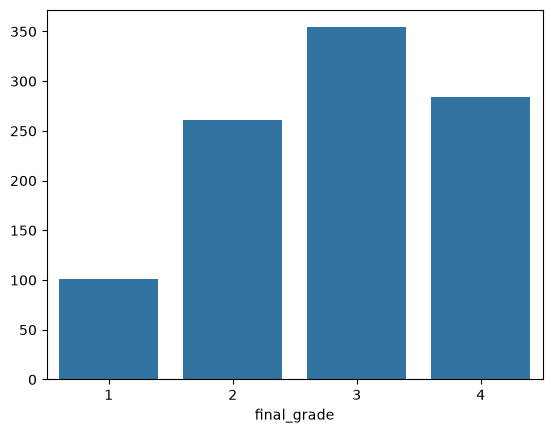

In [37]:
import seaborn as sns

gradeVal = df['final_grade'].value_counts()
sns.barplot(x=gradeVal.index, y=gradeVal.values)

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [5, 7, 9, 11, None],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2', None],
    'criterion': ['gini', 'entropy'],
}

random_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_dist, n_iter=20, cv=5, scoring='accuracy', random_state=42
)
random_search.fit(X_train, y_train)

print(f"Migliori parametri: {random_search.best_params_}")
print(f"Miglior accuracy in CV: {random_search.best_score_:.4f}")

Migliori parametri: {'n_estimators': 100, 'min_samples_split': 2, 'max_features': 'log2', 'max_depth': 11, 'criterion': 'entropy'}
Miglior accuracy in CV: 0.5157


In [20]:
from sklearn.metrics import classification_report

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=11,
    min_samples_split=2,
    max_features='log2',
    criterion='entropy',
    class_weight='balanced',
    random_state=42
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.30      0.26      0.28        31
           2       0.47      0.53      0.50        78
           3       0.52      0.45      0.48       106
           4       0.68      0.74      0.71        85

    accuracy                           0.53       300
   macro avg       0.49      0.49      0.49       300
weighted avg       0.53      0.53      0.53       300



study_time_hours                  0.288121
previous_grade                    0.217691
attendance_percent                0.173782
sleep_hours                       0.135282
parental_education                0.061618
part_time_job_Yes                 0.037221
internet_access_Yes               0.034017
extracurricular_activities_Yes    0.026385
gender_Male                       0.025883
dtype: float64


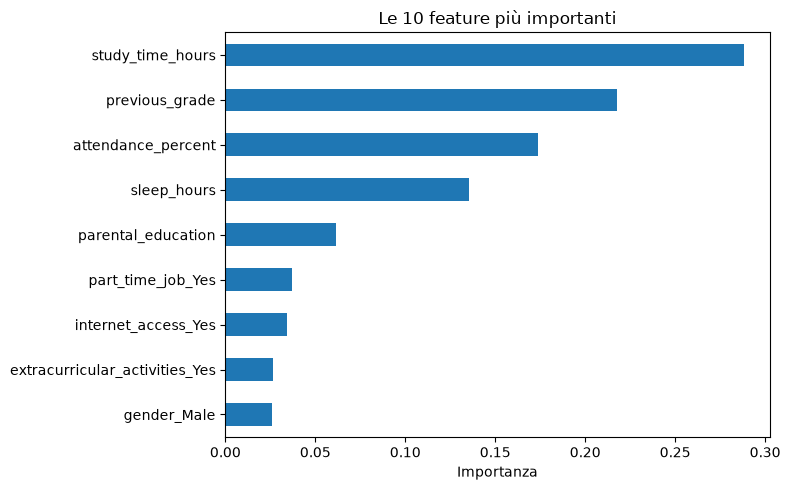

In [21]:
import matplotlib.pyplot as plt

importanze = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importanze)

plt.figure(figsize=(8, 5))
importanze.head(10).plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel("Importanza")
plt.title("Le 10 feature più importanti")
plt.tight_layout()
plt.show()